                         state                 rto   count
0     Andaman & Nicobar Island      Port Blair DTO  190689
1               Andhra Pradesh           Adoni RTO  263708
2               Andhra Pradesh      Amalapuram RTA  278026
3               Andhra Pradesh      Anakapalli RTA  575922
4               Andhra Pradesh       Anantapur RTA  653369
...                        ...                 ...     ...
1451               West Bengal      SRIRAMPUR ARTO  238030
1452               West Bengal          TAMLUK RTO  439756
1453               West Bengal        TEHATTA ARTO   12020
1454               West Bengal       ULUBERIA ARTO  239232
1455               West Bengal  UTTAR DINAJPUR RTO  340288

[1456 rows x 3 columns]
53352.25 412255.75
-485003.0 950611.0
               state                                 rto    count
23    Andhra Pradesh                          Guntur RTA  1086197
81    Andhra Pradesh                      Vijayawada RTA  1141503
82    Andhra Pradesh           

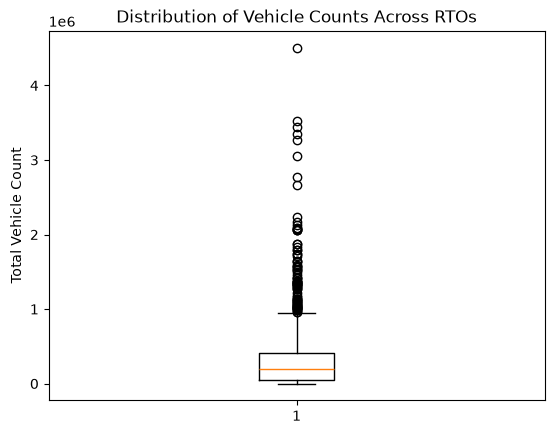

mean: 317133.2864010989
Median: 189326.5
skewed 3.455927597285006
Highest normal value: 943921
Lowest outlier: 956799
          state        rto   count
1266  Telangana  RTA UPPAL  956799
Total records: 203
Unique manufacturers: 203
Total registrations: 956799


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv("vehicle.csv")
res=df.groupby(["state", "rto"],as_index=False)["count"].sum()
print(res)
q1=res["count"].quantile(0.25)
q3=res["count"].quantile(0.75)
print(q1,q3)
IQR=q3-q1
lower=q1-(1.5*IQR)
upper=q3+(1.5*IQR)
print(lower,upper)
outliers = res[
    (res["count"] < lower) |
    (res["count"] > upper)
]

percentage = (len(outliers) / len(res)) * 100
print(outliers,percentage)
outliers.sort_values(
    by="count",
    ascending=False
)[["state", "rto", "count"]].head(10)
plt.boxplot(res["count"])

plt.title("Distribution of Vehicle Counts Across RTOs")
plt.ylabel("Total Vehicle Count")

plt.show()
median_value = res["count"].median()
print("mean:", res["count"].mean())
print("Median:", median_value)
print("skewed",res["count"].skew())
print("Highest normal value:",
      res[res["count"] <= upper]["count"].max())

print("Lowest outlier:",
      res[res["count"] > upper]["count"].min())
print(
    res[res["count"] == 956799]
    [["state", "rto", "count"]]
)
uppal = df[
    (df["state"] == "Telangana") &
    (df["rto"] == "RTA UPPAL")
]

print("Total records:", len(uppal))
print("Unique manufacturers:", uppal["maker"].nunique())
print("Total registrations:", uppal["count"].sum())